In [1]:
import os, json, glob, random, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from IPython.display import clear_output

random.seed(42)

# ---- EDIT THESE IF NEEDED ----
DATA_DIR = Path('35_38_all_class')      # where your images + json labels live
WORK_DIR = Path('/media/avidmech/5f24ef25-197a-42b3-9359-3c9991c059ef/object detetcion_ glove_mask_fallen_objects')               # where the YOLO-format dataset gets built

# --------------------------------

IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp'}
WORK_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
def find_image_json_pairs(data_dir):
    pairs = []
    for img_path in data_dir.rglob('*'):
        if img_path.suffix.lower() in IMAGE_EXTS:
            json_path = img_path.with_suffix('.json')
            if json_path.exists():
                pairs.append((img_path, json_path))
    return pairs

pairs = find_image_json_pairs(DATA_DIR)
print(f"Found {len(pairs)} image/label pairs in {DATA_DIR}")

if len(pairs) == 0:
    raise FileNotFoundError(
        f"No image+json pairs found under {DATA_DIR}. "
        "Check that each image has a same-named .json file next to it."
    )

# Auto-detect classes from every JSON file
class_set = set()
skipped_json = 0
for _, json_path in pairs:
    try:
        with open(json_path, 'r') as f:
            data = json.load(f)
        for shape in data.get('shapes', []):
            class_set.add(shape['label'])
    except Exception as e:
        skipped_json += 1

classes = sorted(class_set)
class_to_id = {c: i for i, c in enumerate(classes)}

print(f"Detected {len(classes)} classes: {classes}")
if skipped_json:
    print(f"Warning: {skipped_json} json files could not be parsed and were skipped.")

Found 6462 image/label pairs in 35_38_all_class
Detected 9 classes: ['albag', 'gloved', 'masked', 'pcs', 'person', 'tray', 'tray_red', 'ungloved', 'unmasked']


In [3]:
def polygon_to_bbox(points):
    """Works for both 'rectangle' (2 points) and 'polygon' (N points) shapes."""
    xs = [p[0] for p in points]
    ys = [p[1] for p in points]
    return min(xs), min(ys), max(xs), max(ys)

def get_image_size(json_data, img_path):
    w = json_data.get('imageWidth')
    h = json_data.get('imageHeight')
    if not w or not h:
        with Image.open(img_path) as im:
            w, h = im.size
    return w, h

def labelme_to_yolo_lines(json_path, img_path, class_to_id):
    with open(json_path, 'r') as f:
        data = json.load(f)
    img_w, img_h = get_image_size(data, img_path)

    lines = []
    for shape in data.get('shapes', []):
        label = shape.get('label')
        if label not in class_to_id:
            continue
        cls_id = class_to_id[label]
        x_min, y_min, x_max, y_max = polygon_to_bbox(shape['points'])

        # clip to image bounds
        x_min, x_max = max(0, x_min), min(img_w, x_max)
        y_min, y_max = max(0, y_min), min(img_h, y_max)
        bw, bh = x_max - x_min, y_max - y_min
        if bw <= 0 or bh <= 0:
            continue

        x_center = (x_min + bw / 2) / img_w
        y_center = (y_min + bh / 2) / img_h
        w_norm = bw / img_w
        h_norm = bh / img_h
        lines.append(f"{cls_id} {x_center:.6f} {y_center:.6f} {w_norm:.6f} {h_norm:.6f}")
    return lines

In [4]:
random.shuffle(pairs)
split_idx = int(0.8 * len(pairs))
train_pairs, val_pairs = pairs[:split_idx], pairs[split_idx:]

for split, split_pairs in [('train', train_pairs), ('val', val_pairs)]:
    (WORK_DIR / 'images' / split).mkdir(parents=True, exist_ok=True)
    (WORK_DIR / 'labels' / split).mkdir(parents=True, exist_ok=True)

    for img_path, json_path in split_pairs:
        lines = labelme_to_yolo_lines(json_path, img_path, class_to_id)

        dst_img = WORK_DIR / 'images' / split / img_path.name
        shutil.copy(img_path, dst_img)

        dst_label = WORK_DIR / 'labels' / split / (img_path.stem + '.txt')
        with open(dst_label, 'w') as f:
            f.write('\n'.join(lines))

print(f"Train: {len(train_pairs)} images | Val: {len(val_pairs)} images")

yaml_lines = [f"path: {WORK_DIR}", "train: images/train", "val: images/val", "", "names:"]
for i, c in enumerate(classes):
    yaml_lines.append(f"  {i}: {c}")

yaml_path = WORK_DIR / 'data.yaml'
with open(yaml_path, 'w') as f:
    f.write('\n'.join(yaml_lines))

print("\n" + '\n'.join(yaml_lines))

Train: 5169 images | Val: 1293 images

path: /media/avidmech/5f24ef25-197a-42b3-9359-3c9991c059ef/object detetcion_ glove_mask_fallen_objects
train: images/train
val: images/val

names:
  0: albag
  1: gloved
  2: masked
  3: pcs
  4: person
  5: tray
  6: tray_red
  7: ungloved
  8: unmasked


In [ ]:
def show_examples_per_class(pairs, classes, n_examples=5):
    for cls in classes:
        matching = []
        for img_path, json_path in pairs:
            with open(json_path) as f:
                data = json.load(f)
            labels_here = {s.get('label') for s in data.get('shapes', [])}
            if cls in labels_here:
                matching.append((img_path, json_path))

        if not matching:
            print(f"No images found for class '{cls}', skipping.")
            continue

        sample = random.sample(matching, min(n_examples, len(matching)))
        fig, axes = plt.subplots(1, len(sample), figsize=(4 * len(sample), 4))
        if len(sample) == 1:
            axes = [axes]
        fig.suptitle(f"Label: {cls}  ({len(matching)} images total)", fontsize=14)

        for ax, (img_path, json_path) in zip(axes, sample):
            img = Image.open(img_path).convert('RGB')
            ax.imshow(img)
            with open(json_path) as f:
                data = json.load(f)
            for shape in data.get('shapes', []):
                if shape.get('label') != cls:
                    continue
                x_min, y_min, x_max, y_max = polygon_to_bbox(shape['points'])
                rect = patches.Rectangle(
                    (x_min, y_min), x_max - x_min, y_max - y_min,
                    linewidth=2, edgecolor='lime', facecolor='none'
                )
                ax.add_patch(rect)
            ax.axis('off')

        plt.tight_layout()
        plt.show()


show_examples_per_class(pairs, classes, n_examples=5)

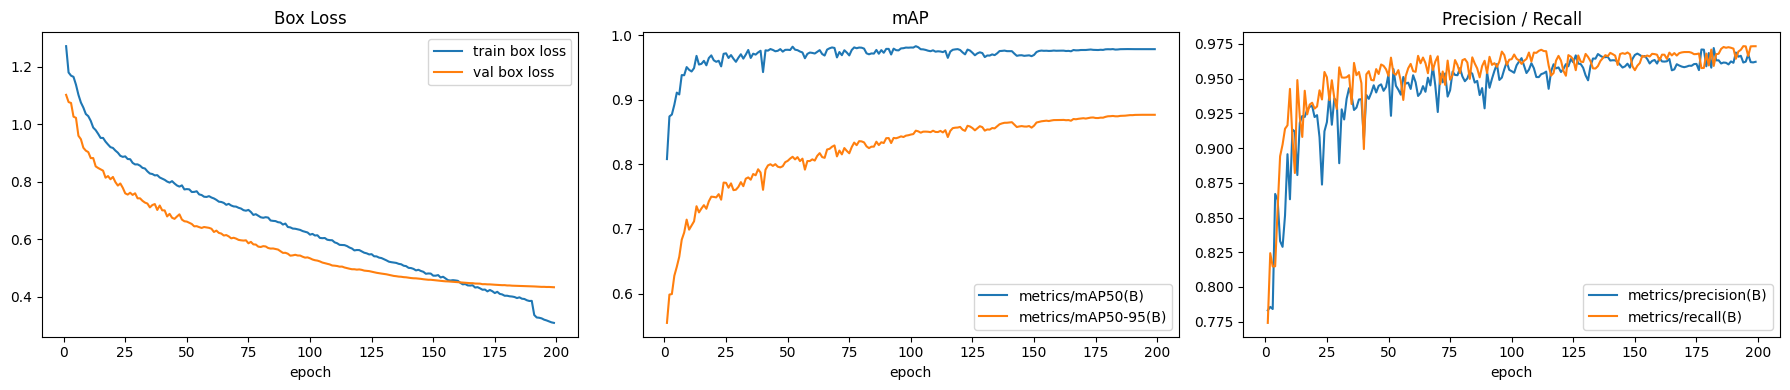

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 122/122 4.4it/s 27.7s0.2s
                   all       1950      20961      0.968      0.967      0.978      0.877

200 epochs completed in 25.199 hours.
Optimizer stripped from /media/avidmech/5f24ef25-197a-42b3-9359-3c9991c059ef/object detetcion_ glove_mask_fallen_objects/runs/detect/runs/4Class_OD_yolo26x-3/weights/last.pt, 118.4MB
Optimizer stripped from /media/avidmech/5f24ef25-197a-42b3-9359-3c9991c059ef/object detetcion_ glove_mask_fallen_objects/runs/detect/runs/4Class_OD_yolo26x-3/weights/best.pt, 118.4MB

Validating /media/avidmech/5f24ef25-197a-42b3-9359-3c9991c059ef/object detetcion_ glove_mask_fallen_objects/runs/detect/runs/4Class_OD_yolo26x-3/weights/best.pt...
Ultralytics 8.4.136 🚀 Python-3.10.21 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3090, 24260MiB)
YOLO26x summary (fused): 190 layers, 55,643,943 parameters, 0 gradients, 194.0 GFLOPs
                 Class 

In [6]:
from ultralytics import YOLO
DEVICE      = 0                # GPU index; "cpu" to force CPU
PATIENCE    = 50               # early stopping: stop if no val improvement for N epochs
EPOCHS   = 200
IMG_SIZE = 1024
BATCH    = 8
MODEL_WEIGHTS = 'yolo26x.pt'                           # swap for yolo26s/m/l/x.pt for more accuracy

model = YOLO(MODEL_WEIGHTS)

def plot_live_metrics(trainer):
    csv_path = trainer.save_dir / 'results.csv'
    if not csv_path.exists():
        return
    df = pd.read_csv(csv_path)
    df.columns = [c.strip() for c in df.columns]

    clear_output(wait=True)
    fig, axes = plt.subplots(1, 3, figsize=(18, 4))

    if 'train/box_loss' in df.columns:
        axes[0].plot(df['epoch'], df['train/box_loss'], label='train box loss')
    if 'val/box_loss' in df.columns:
        axes[0].plot(df['epoch'], df['val/box_loss'], label='val box loss')
    axes[0].set_title('Box Loss'); axes[0].set_xlabel('epoch'); axes[0].legend()

    map_cols = [c for c in df.columns if 'mAP' in c]
    for c in map_cols:
        axes[1].plot(df['epoch'], df[c], label=c)
    axes[1].set_title('mAP'); axes[1].set_xlabel('epoch'); axes[1].legend()

    pr_cols = [c for c in df.columns if 'precision' in c.lower() or 'recall' in c.lower()]
    for c in pr_cols:
        axes[2].plot(df['epoch'], df[c], label=c)
    axes[2].set_title('Precision / Recall'); axes[2].set_xlabel('epoch'); axes[2].legend()

    plt.tight_layout()
    plt.show()

model.add_callback('on_train_epoch_end', plot_live_metrics)

results = model.train(
    data=str(yaml_path),
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH,
    project='runs',
    name='4Class_OD_yolo26x',
    plots=True,
    device=DEVICE,
    patience=PATIENCE
)

Training complete. Full run artifacts saved to: /media/avidmech/5f24ef25-197a-42b3-9359-3c9991c059ef/object detetcion_ glove_mask_fallen_objects/runs/detect/runs/4Class_OD_yolo26x-3


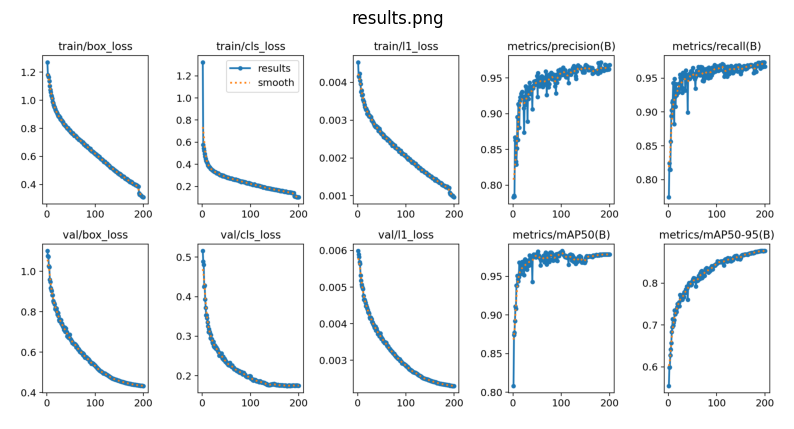

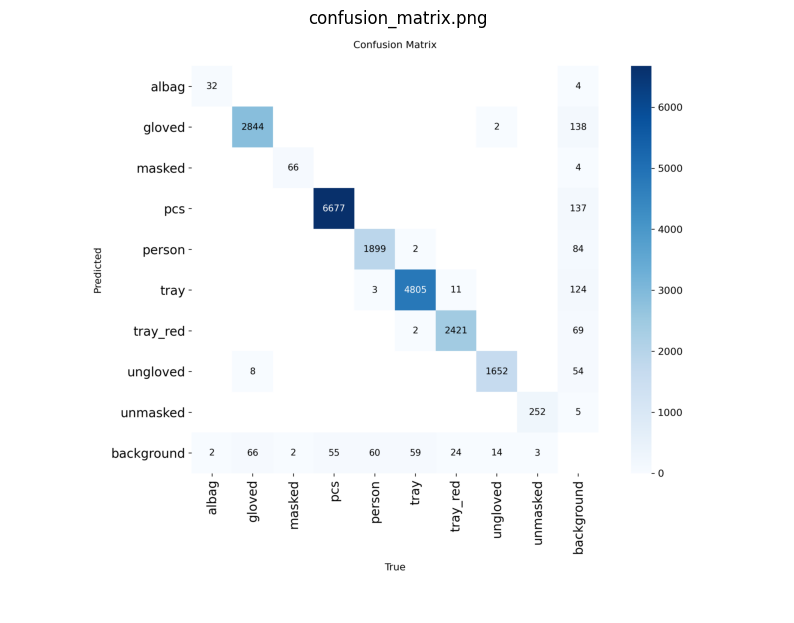

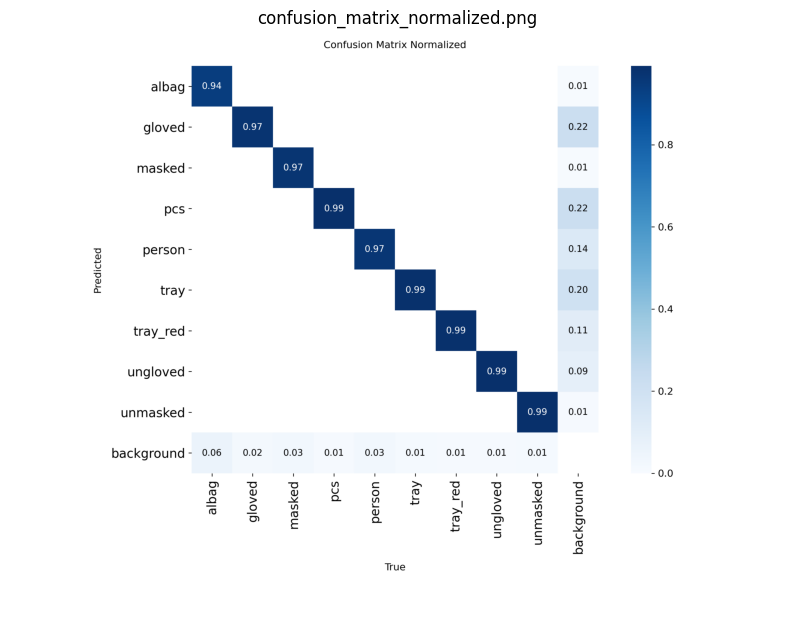

In [7]:
save_dir = Path(results.save_dir)
print("Training complete. Full run artifacts saved to:", save_dir)

for img_name in ['results.png', 'confusion_matrix.png', 'confusion_matrix_normalized.png', 'PR_curve.png']:
    img_path = save_dir / img_name
    if img_path.exists():
        plt.figure(figsize=(10, 8))
        plt.imshow(Image.open(img_path))
        plt.axis('off')
        plt.title(img_name)
        plt.show()

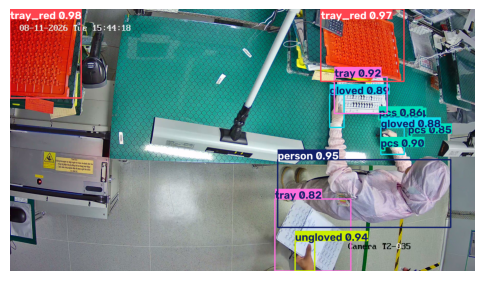

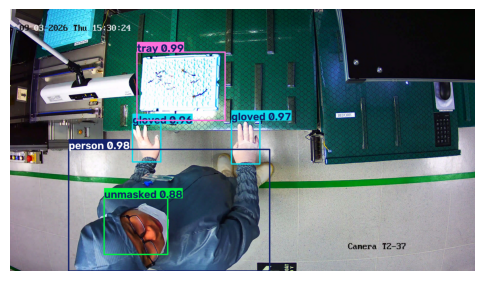

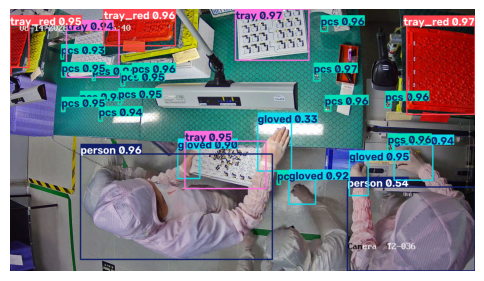

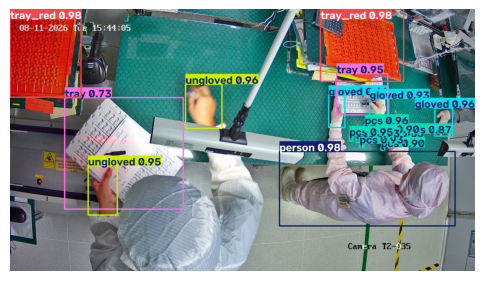

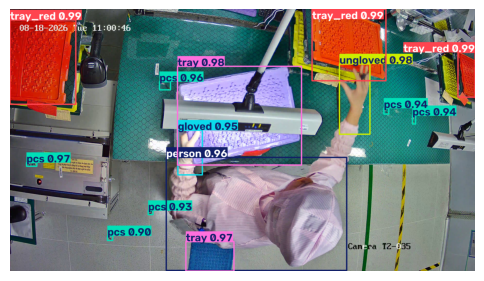

In [8]:
best_model = YOLO(save_dir / 'weights' / 'best.pt')

val_images = list((WORK_DIR / 'images' / 'val').glob('*'))
sample_val = random.sample(val_images, min(5, len(val_images)))

pred_results = best_model.predict(sample_val, save=False, verbose=False)

for r in pred_results:
    im_array = r.plot()  # BGR numpy array with boxes drawn
    plt.figure(figsize=(6, 6))
    plt.imshow(im_array[..., ::-1])  # BGR -> RGB
    plt.axis('off')
    plt.show()

In [ ]:
# ─────────────────────────────────────────────────────────────
# VIDEO INFERENCE (YOLO) — run the trained model on a video and
# save an annotated copy, with big/clear boxes+labels, at 30 FPS
# ─────────────────────────────────────────────────────────────
import cv2
import numpy as np
from tqdm import tqdm
from ultralytics import YOLO
import supervision as sv

SOURCE_VIDEO_PATH = "rfdetr_runs/done_D28_20260829154004_PCS_Ungloved.mp4"          # <-- set this
TARGET_VIDEO_PATH = "output_annotated_detcted_new.mp4"     # <-- set this
CONFIDENCE_THRESHOLD = 0.60
OUTPUT_FPS = 60         # forces the output container's fps metadata to 30
MAX_FRAMES = None        # e.g. 30 to only process the first 30 frames for a quick test

# Standard Ultralytics layout: <save_dir>/weights/best.pt
best_weights = "runs/detect/runs/4Class_OD_yolo26x-3/weights/best.pt"
model = YOLO(str(best_weights))

# Big, clear annotation style — bump further if it's still too small
# for your resolution (e.g. text_scale=1.6, thickness=6 for 4K video)
box_annotator = sv.BoxAnnotator(thickness=4)
label_annotator = sv.LabelAnnotator(
    text_scale=1.2,
    text_thickness=2,
    text_padding=10,
)

source_info = sv.VideoInfo.from_video_path(SOURCE_VIDEO_PATH)
target_info = sv.VideoInfo(
    width=source_info.width,
    height=source_info.height,
    fps=OUTPUT_FPS,
    total_frames=source_info.total_frames,
)

frame_generator = sv.get_video_frames_generator(
    source_path=SOURCE_VIDEO_PATH,
    end=MAX_FRAMES,
)
total_to_process = MAX_FRAMES or source_info.total_frames

with sv.VideoSink(target_path=TARGET_VIDEO_PATH, video_info=target_info) as sink:
    for frame in tqdm(frame_generator, total=total_to_process, desc="Annotating video"):
        # YOLO accepts the raw BGR numpy frame directly — no PIL conversion needed
        result = model(frame, conf=CONFIDENCE_THRESHOLD, verbose=False)[0]
        detections = sv.Detections.from_ultralytics(result)

        labels = [
            f"{model.names[class_id]} {conf:.2f}"
            for class_id, conf in zip(detections.class_id, detections.confidence)
        ]

        annotated = box_annotator.annotate(frame.copy(), detections)
        annotated = label_annotator.annotate(annotated, detections, labels)
        sink.write_frame(annotated)

print(f"Done — annotated video saved to {TARGET_VIDEO_PATH}")